In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_json("../data/fridge_history.json")
print(df.head())
print(df.shape)
print(df.info())

   id          name   category        barcode  added_date expiry_date  \
0   1   Minced meat       meat  2238849696537  2025-09-01  2025-09-05   
1   2       Carrots  vegetable  2098050097888  2025-09-01  2025-09-27   
2   3   Bell pepper  vegetable  2543534624758  2025-09-01  2025-09-10   
3   4        Cheese      dairy  2255341928324  2025-09-01  2025-10-09   
4   5  Ring sausage       meat  2514627048287  2025-09-01  2025-09-21   

  opened_date removed_date outcome consumed_by  dish_id  
0  2025-09-03   2025-09-03   eaten        dish      3.0  
1  2025-09-05   2025-09-18   eaten       snack      NaN  
2  2025-09-02   2025-09-03   eaten       snack      NaN  
3  2025-09-02   2025-09-18   eaten        dish      3.0  
4  2025-09-02   2025-09-09   eaten       snack      NaN  
(784, 11)
<class 'pandas.DataFrame'>
RangeIndex: 784 entries, 0 to 783
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            784 

outcome
eaten     642
wasted    142
Name: count, dtype: int64


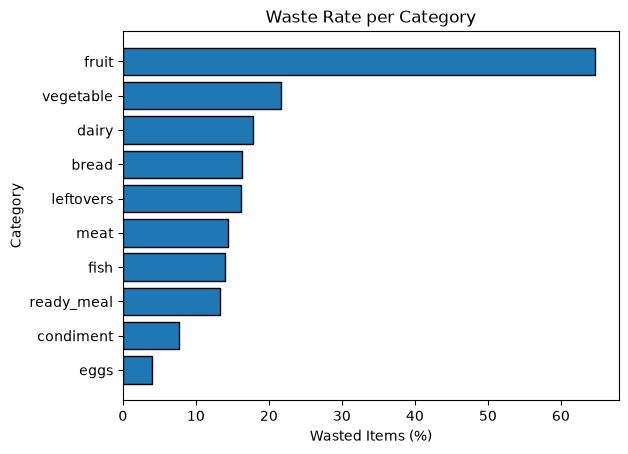

In [2]:
df["wasted"] = (df["outcome"] == "wasted").astype(int)
print(df["outcome"].value_counts())
waste_rate = df.groupby("category")["wasted"].mean().sort_values()
plt.barh(waste_rate.index, waste_rate.values * 100, edgecolor="black")
plt.xlabel("Wasted Items (%)")
plt.ylabel("Category")
plt.title("Waste Rate per Category")
plt.show()

General data overview is above.

Below, "days_until_expiry" is the interval between buy date (or rather when user scans it) and product's expiry date. Printed 5 rows for showcase. 

In [3]:
df["added_date"] = pd.to_datetime(df["added_date"])
df["expiry_date"] = pd.to_datetime(df["expiry_date"])
df["days_until_expiry"] = (df["expiry_date"] - df["added_date"]).dt.days
df["weekday_added"] = df["added_date"].dt.day_of_week
print(df[["name", "category", "days_until_expiry", "weekday_added", "wasted"]].head())

           name   category  days_until_expiry  weekday_added  wasted
0   Minced meat       meat                  4              0       0
1       Carrots  vegetable                 26              0       0
2   Bell pepper  vegetable                  9              0       0
3        Cheese      dairy                 38              0       0
4  Ring sausage       meat                 20              0       0


Down below, instead of using test_train_split, we split dataset by time. Total dataset duration is 12 months, we use first 9 for training (639 records) and then 3 for testing (145 records).

In [4]:
train = df[df["added_date"] < "2026-06-01"].copy()
test = df[df["added_date"] >= "2026-06-01"].copy()
print(len(train))
print(len(test))

639
145


In [5]:
product_rate = train.groupby("name")["wasted"].mean()
train["product_waste_rate"] = train["name"].map(product_rate)
test["product_waste_rate"] = test["name"].map(product_rate).fillna(train["wasted"].mean())
print(product_rate.sort_values(ascending=False).head(10).round(2))

name
Christmas ham                     1.00
Cream cheese                      0.75
Sour cream                        0.75
Grapes                            0.64
Pickled herring                   0.50
Toast bread                       0.43
Macaroni casserole (leftovers)    0.40
Broccoli                          0.38
Sliced ham                        0.36
Lettuce                           0.35
Name: wasted, dtype: float64


Waste rates of rarely bought products are unreliable. Christmas ham (100% waste rate) in the dataset was bought only once, and then trashed. Frequently bought products like broccoli (21 purchases) and lettuce (20) show more reliable patterns.

Right now we have 3 numeric features, the category so far is text. We cannot feed text into a model, so below we convert category into a wide boolean table.

In [6]:
features = ["days_until_expiry", "weekday_added", "product_waste_rate", "category"]
X_train = pd.get_dummies(train[features], columns=["category"])
X_test = pd.get_dummies(test[features], columns=["category"])
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
y_train = train["wasted"]
y_test = test["wasted"]
print(X_train.head())

   days_until_expiry  weekday_added  product_waste_rate  category_bread  \
0                  4              0            0.068966           False   
1                 26              0            0.055556           False   
2                  9              0            0.076923           False   
3                 38              0            0.176471           False   
4                 20              0            0.222222           False   

   category_condiment  category_dairy  category_eggs  category_fish  \
0               False           False          False          False   
1               False           False          False          False   
2               False           False          False          False   
3               False            True          False          False   
4               False           False          False          False   

   category_fruit  category_leftovers  category_meat  category_ready_meal  \
0           False               False        

At first, test two models. DecisionTreeClassifier and GaussianNB.

Tree depth of 4 is due to how small current dataset is. If we would increase it, we risk overfitting the model.

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
tree = DecisionTreeClassifier(
 max_depth=4,
 class_weight="balanced",
 random_state=42
)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_gnb = gnb.predict(X_test)

In [8]:
from sklearn.metrics import (
 accuracy_score,
 confusion_matrix,
 classification_report
)
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))
print(classification_report(
 y_test,
 y_pred_tree,
 target_names=["eaten", "wasted"]
))

Accuracy: 0.6896551724137931
Confusion Matrix:
[[88 29]
 [16 12]]
              precision    recall  f1-score   support

       eaten       0.85      0.75      0.80       117
      wasted       0.29      0.43      0.35        28

    accuracy                           0.69       145
   macro avg       0.57      0.59      0.57       145
weighted avg       0.74      0.69      0.71       145



Model Accuracy = 69%

88+29=117 products were actually eaten. Model predicted 29 of them as wasted (false alarm). 

16+12=28 products were wasted, and the model successfully predicted only 12 of them.

The model found 12 of the 28 (43%) wasted items, and only 29% of its wasted predictions were correct. That's primarily caused by data, not the model, and the fact that in dataset, most causes of waste happen after the purchase, due to unexpected events.

Real world data would most likely behave the same way or worse, since real waste is also driven by everyday randomness. So the result is pretty much realistic.

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
models = {
 "Decision Tree": tree,
 "GaussianNB": gnb
}
results = [{
 "Model": "Always eaten",
 "Accuracy": accuracy_score(y_test, [0] * len(y_test)),
 "Precision": 0,
 "Recall": 0,
 "F1": 0,
 "ROC AUC": 0.5
}]
for name, model in models.items():
 y_pred = model.predict(X_test)
 results.append({
 "Model": name,
 "Accuracy": accuracy_score(y_test, y_pred),
 "Precision": precision_score(y_test, y_pred, zero_division=0),
 "Recall": recall_score(y_test, y_pred),
 "F1": f1_score(y_test, y_pred),
 "ROC AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
 })
results_df = pd.DataFrame(results)
print(results_df.round(3))

           Model  Accuracy  Precision  Recall     F1  ROC AUC
0   Always eaten     0.807      0.000   0.000  0.000    0.500
1  Decision Tree     0.690      0.293   0.429  0.348    0.593
2     GaussianNB     0.724      0.269   0.250  0.259    0.609


F1 scores are also weak. Ideally we would aim for F1 > 0.5. ROC AUC is also pretty weak and tells that current model is slightly better than pure guessing.

In [10]:
probabilities = tree.predict_proba(X_test)
print(test[["name", "days_until_expiry", "outcome"]].head())
print(probabilities[:5].round(2))

                         name  days_until_expiry outcome
639  Oven pancake (leftovers)                  3   eaten
640                      Milk                 11   eaten
641             Karelian pies                  1  wasted
642               Minced meat                  3   eaten
643                     Bacon                 19   eaten
[[0.33 0.67]
 [0.69 0.31]
 [0.07 0.93]
 [0.69 0.31]
 [1.   0.  ]]


In the matrix above, the 1st col is the probability of eaten and the 2nd is the probability of wasted.

So far the model predicted only once, when the product was scanned. However, we can also review the case when it predicts on an everyday basis. Most causes of waste happen after the purchase, so a daily prediction can use new information, such as days left and whether the item was opened

In [11]:
catalogue = pd.read_json("../data/products_catalogue.json")
opened_life = dict(zip(catalogue["name"], catalogue["opened_shelf_life_days"]))
df["opened_date"] = pd.to_datetime(df["opened_date"])
df["removed_date"] = pd.to_datetime(df["removed_date"])
print(catalogue.head())

            name category  shelf_life_days  opened_shelf_life_days
0           Milk    dairy               10                       6
1         Yogurt    dairy               18                       7
2          Quark    dairy               21                       3
3     Sour cream    dairy               18                       5
4  Cooking cream    dairy               30                       4


The following extends loaded dataset table into a new daily table, so that every row is one whole day per single item. We walk from purchase date to removal date and records what app knows about that product each day.

In [12]:
rows = []
for _, item in df.iterrows():
 day = item["added_date"]

 while day <= item["removed_date"]:
  opened = pd.notna(item["opened_date"]) and item["opened_date"] < day
  last_good_day = item["expiry_date"]

  if opened and item["name"] in opened_life:
   opened_limit = item["opened_date"] + pd.Timedelta(days=opened_life[item["name"]])
   last_good_day = min(last_good_day, opened_limit)

  days_left = (last_good_day - day).days
  if days_left < 0:
   break
  
  rows.append({
   "id": item["id"],
   "name": item["name"],
   "category": item["category"],
   "added_date": item["added_date"],
   "days_left": days_left,
   "opened": int(opened),
   "days_since_added": (day - item["added_date"]).days,
   "weekday": day.weekday(),
   "wasted": item["wasted"]
  })

  day = day + pd.Timedelta(days=1)
  
daily = pd.DataFrame(rows)
print(daily.head())
print(daily.shape)

   id         name   category added_date  days_left  opened  days_since_added  \
0   1  Minced meat       meat 2025-09-01          4       0                 0   
1   1  Minced meat       meat 2025-09-01          3       0                 1   
2   1  Minced meat       meat 2025-09-01          2       0                 2   
3   2      Carrots  vegetable 2025-09-01         26       0                 0   
4   2      Carrots  vegetable 2025-09-01         25       0                 1   

   weekday  wasted  
0        0       0  
1        1       0  
2        2       0  
3        0       0  
4        1       0  
(5993, 9)


Split the data again by time and into train/test

In [13]:
daily_train = daily[daily["added_date"] < "2026-06-01"]
daily_test = daily[daily["added_date"] >= "2026-06-01"].copy()
daily_features = ["days_left", "opened", "days_since_added", "weekday", "category"]
X_train_d = pd.get_dummies(daily_train[daily_features], columns=["category"])
X_test_d = pd.get_dummies(daily_test[daily_features], columns=["category"])
X_test_d = X_test_d.reindex(columns=X_train_d.columns, fill_value=0)
y_train_d = daily_train["wasted"]
y_test_d = daily_test["wasted"]
print(len(X_train_d))
print(len(X_test_d))

4985
1008


Added more models to see how they perform. We will pick the one with best recall and precision.

Tested models (7): Decision Tree, GaussianNB, Logistic Regression, LDA, QDA, Random Forest, K-Nearest Neighbours

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
tree_d = DecisionTreeClassifier(
 max_depth=4,
 class_weight="balanced",
 random_state=42
)
tree_d.fit(X_train_d, y_train_d)
logreg_d = LogisticRegression(
 class_weight="balanced",
 max_iter=1000
)
logreg_d.fit(X_train_d, y_train_d)
gnb_d = GaussianNB()
gnb_d.fit(X_train_d, y_train_d)
lda_d = LinearDiscriminantAnalysis()
lda_d.fit(X_train_d, y_train_d)
qda_d = QuadraticDiscriminantAnalysis(reg_param=0.1)
qda_d.fit(X_train_d, y_train_d)
forest_d = RandomForestClassifier(
 n_estimators=100,
 max_depth=6,
 class_weight="balanced",
 random_state=42
)
forest_d.fit(X_train_d, y_train_d)
knn_d = KNeighborsClassifier(n_neighbors=25)
knn_d.fit(X_train_d, y_train_d)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",25
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [15]:
from sklearn.metrics import f1_score
models_d = {
 "Decision Tree": tree_d,
 "Logistic Regression": logreg_d,
 "GaussianNB": gnb_d,
 "LDA": lda_d,
 "QDA": qda_d,
 "Random Forest": forest_d,
 "KNN": knn_d
}
results_d = [{
 "Model": "Always eaten",
 "Accuracy": accuracy_score(y_test_d, [0] * len(y_test_d)),
 "Precision": 0,
 "Recall": 0,
 "F1": 0,
 "ROC AUC": 0.5
}, {
 "Model": "Days-left rule",
 "Accuracy": accuracy_score(y_test_d, daily_test["days_left"] <= 2),
 "Precision": precision_score(y_test_d, daily_test["days_left"] <= 2),
 "Recall": recall_score(y_test_d, daily_test["days_left"] <= 2),
 "F1": f1_score(y_test_d, daily_test["days_left"] <= 2),
 "ROC AUC": roc_auc_score(y_test_d, -daily_test["days_left"])
}]
for name, model in models_d.items():
 y_pred = model.predict(X_test_d)
 results_d.append({
 "Model": name,
 "Accuracy": accuracy_score(y_test_d, y_pred),
 "Precision": precision_score(y_test_d, y_pred, zero_division=0),
 "Recall": recall_score(y_test_d, y_pred),
 "F1": f1_score(y_test_d, y_pred),
 "ROC AUC": roc_auc_score(y_test_d, model.predict_proba(X_test_d)[:, 1])
 })
results_d_df = pd.DataFrame(results_d)
print(results_d_df.round(3))

                 Model  Accuracy  Precision  Recall     F1  ROC AUC
0         Always eaten     0.709      0.000   0.000  0.000    0.500
1       Days-left rule     0.689      0.446   0.283  0.347    0.647
2        Decision Tree     0.680      0.465   0.683  0.553    0.712
3  Logistic Regression     0.552      0.363   0.717  0.482    0.670
4           GaussianNB     0.587      0.156   0.096  0.119    0.633
5                  LDA     0.717      0.600   0.082  0.144    0.663
6                  QDA     0.639      0.274   0.147  0.191    0.636
7        Random Forest     0.661      0.447   0.703  0.546    0.720
8                  KNN     0.733      0.582   0.290  0.387    0.719


Previously tested GaussianNB showed great decline in precision and recall.
Previously tested Decision Tree performed much better and now has the highest F1 score among all of the models (combination of precision and recall). ROC AUC also improved by far and is now at acceptable rates. To be fair, they were measured on different dataset tables, but we care only about the end result.

Factually, Decision Tree and Random Forest are tied here, so we might pick the one with highest F1 score.

In [16]:
daily_test["tree_warning"] = tree_d.predict(X_test_d)
daily_test["forest_warning"] = forest_d.predict(X_test_d)
rule_first = daily_test[daily_test["days_left"] <= 2].groupby("id").first()
tree_first = daily_test[daily_test["tree_warning"] == 1].groupby("id").first()
forest_first = daily_test[daily_test["forest_warning"] == 1].groupby("id").first()
comparison = pd.DataFrame({
 "Model": [
 "Days-left rule",
 "Decision Tree",
 "Random Forest"
 ],
 "Wasted Warned": [
 rule_first["wasted"].sum(),
 tree_first["wasted"].sum(),
 forest_first["wasted"].sum()
 ],
 "Days Before Waste": [
 rule_first[rule_first["wasted"] == 1]["days_left"].mean(),
 tree_first[tree_first["wasted"] == 1]["days_left"].mean(),
 forest_first[forest_first["wasted"] == 1]["days_left"].mean()
 ],
 "Eaten Warned": [
 (rule_first["wasted"] == 0).sum(),
 (tree_first["wasted"] == 0).sum(),
 (forest_first["wasted"] == 0).sum()
 ]
})
print(comparison.round(1))

            Model  Wasted Warned  Days Before Waste  Eaten Warned
0  Days-left rule             28                2.0            65
1   Decision Tree             27                6.9            62
2   Random Forest             28                7.5            73


Days left rule - automatic notification 2 days before the item goes bad (the expiry date, or the end of shelf life after opening, whichever is earlier).

Days Before Waste - Average warning before spoiling in days.

Eaten Warned - false positives. Items that got a warning but were eaten in the end.

Decision Tree previously provided 12/28 correct waste predictions and now sits at 27/28. Random Forest performs slightly better in that regard, but it gives more false alarms. So we will pick the Desicion Tree.

In [17]:
import joblib
joblib.dump(tree_d, "model.joblib")

['model.joblib']